# Task 2: Evaluating Reweighing (Kamiran & Calders, 2012)

Pre-processing pipeline using AIF360's `Reweighing` on three datasets: Adult, German Credit and COMPAS.

Steps follow the assignment:
1. Load three datasets
2. Fairness of the original labels (DP_Diff, DIR, consistency) before any mitigation or model
3. Stratified train/test split
4. Reweighing on the training data only, then train a classifier with the weights
5. DP_Diff, DIR, consistency and accuracy on the held-out test predictions
6. Before vs after comparison

Setup and exact steps to reproduce: see `README.md` in this folder (`pip install -r requirements.txt`, then run all cells).

In [1]:
# In Google Colab, uncomment the next line first:
# !pip install aif360

In [2]:
import os, urllib.request, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# AIF360 0.6.x does not yet work with pandas 3's default string type; this switches it off.
try:
    pd.set_option("future.infer_string", False)
except Exception:
    pass

logging.getLogger().setLevel(logging.ERROR)   # hide AIF360 notices about optional packages Reweighing does not need
import aif360
from aif360.datasets import AdultDataset, GermanDataset, CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
logging.getLogger().setLevel(logging.WARNING)  # keep AIF360's messages about removed rows

warnings.filterwarnings("ignore")

SEEDS = [0, 1, 2, 3, 4]   # repeat the split 5 times and report mean ± std
TEST_SIZE = 0.3
K_NEIGHBORS = 5           # neighbours used for the consistency measure

## 1. Datasets

AIF360 reads the raw files from its own `data/raw` folder. The cell below downloads them there if they are missing.

In [3]:
RAW = os.path.join(os.path.dirname(aif360.__file__), "data", "raw")
FILES = {
    "adult/adult.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    "adult/adult.test": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test",
    "german/german.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data",
    "compas/compas-scores-two-years.csv": "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
}
for rel, url in FILES.items():
    path = os.path.join(RAW, rel)
    if not os.path.exists(path):
        print("downloading", rel)
        urllib.request.urlretrieve(url, path)
print("data folder:", RAW)

data folder: /usr/local/lib/python3.12/dist-packages/aif360/data/raw


Sensitive attribute per dataset (AIF360's standard encoding, privileged group = 1):

| Dataset | Sensitive attribute | Privileged | Unprivileged | Favourable label |
|---|---|---|---|---|
| Adult | sex | male | female | income > 50K |
| German | age | age ≥ 25 | age < 25 | good credit |
| COMPAS | race | Caucasian | not Caucasian | no reoffending within 2 years |

In [4]:
DATASETS = {
    "Adult":  (AdultDataset,  "sex"),
    "German": (GermanDataset, "age"),
    "COMPAS": (CompasDataset, "race"),
}

data = {}
for name, (loader, attr) in DATASETS.items():
    ds = loader()
    data[name] = (ds, attr)
    print(f"{name:7s} rows={ds.features.shape[0]:6d}  features={ds.features.shape[1]:4d}  "
          f"sensitive={attr}  favourable label={ds.favorable_label}")

Adult   rows= 45222  features=  98  sensitive=sex  favourable label=1.0
German  rows=  1000  features=  58  sensitive=age  favourable label=1.0
COMPAS  rows=  6167  features= 401  sensitive=race  favourable label=0.0


## Helper functions

- **DP_Diff** = P(favourable | unprivileged) − P(favourable | privileged). AIF360 calls it `statistical_parity_difference`. Ideal value 0; negative means the unprivileged group is disadvantaged. (The paper's `disc` is the same quantity with the opposite sign.)
- **DIR** = P(favourable | unprivileged) / P(favourable | privileged). Ideal value 1; below 0.8 fails the four-fifths rule.
- **Consistency** = 1 − average difference between each person's label and the mean label of their k nearest neighbours. Ideal value 1 (similar people get similar outcomes). Features are standardised first, otherwise large-scale columns such as income or credit amount dominate the distances.

In [5]:
def groups(attr):
    return [{attr: 0}], [{attr: 1}]   # unprivileged, privileged

def fairness(ds, attr, scaler):
    unpriv, priv = groups(attr)
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=unpriv, privileged_groups=priv)
    return {"DP_Diff": m.statistical_parity_difference(),
            "DIR": m.disparate_impact(),
            "Consistency": consistency(scaler.transform(ds.features), ds.labels.ravel())}

def consistency(X, y, k=K_NEIGHBORS):
    # same formula as AIF360's consistency() (Zemel et al., 2013), but with a fast
    # brute-force neighbour search; AIF360's own version is very slow on Adult
    idx = NearestNeighbors(n_neighbors=k, algorithm="brute").fit(X).kneighbors(X, return_distance=False)
    return float(1 - np.mean(np.abs(y - y[idx].mean(axis=1))))

def stratified_split(ds, attr, seed):
    # stratify on label x sensitive group, so both splits keep the same group/label mix
    s = ds.protected_attributes[:, ds.protected_attribute_names.index(attr)]
    strata = ds.labels.ravel().astype(int).astype(str) + "_" + s.astype(int).astype(str)
    idx_tr, idx_te = train_test_split(np.arange(len(strata)), test_size=TEST_SIZE,
                                      stratify=strata, random_state=seed)
    return ds.subset(idx_tr), ds.subset(idx_te)

def model_inputs(ds, attr):
    # the sensitive attribute itself is not used as a model input (paper's assumption A2)
    keep = [i for i, f in enumerate(ds.feature_names) if f != attr]
    return ds.features[:, keep]

CLASSIFIERS = {
    # stable classifier
    "LogReg": lambda seed: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    # unstable classifier (the paper's experiments suggest preprocessing affects these more)
    "Tree": lambda seed: DecisionTreeClassifier(min_samples_leaf=10, random_state=seed),
}

def train_and_predict(train, test, attr, clf_name, seed, weights=None):
    clf = CLASSIFIERS[clf_name](seed)
    X, y = model_inputs(train, attr), train.labels.ravel()
    if clf_name == "LogReg":
        clf.fit(X, y, logisticregression__sample_weight=weights)
    else:
        clf.fit(X, y, sample_weight=weights)
    pred = test.copy(deepcopy=True)
    pred.labels = clf.predict(model_inputs(test, attr)).reshape(-1, 1)
    return pred

## 2. Fairness of the original labels (before mitigation, no classifier)

In [6]:
before_rows = []
for name, (ds, attr) in data.items():
    scaler = StandardScaler().fit(ds.features)
    r = fairness(ds, attr, scaler)
    before_rows.append({"Dataset": name, **r})
before = pd.DataFrame(before_rows).set_index("Dataset")
before.round(3)

,DP_Diff,DIR,Consistency
Dataset,,,
Adult,-0.199,0.363,0.829
German,-0.149,0.795,0.740
COMPAS,-0.097,0.840,0.668


## 3–5. Stratified split, Reweighing on the training data, evaluation on the test data

For every seed:
- split the data (stratified, 70/30)
- **baseline**: the classifier trained on the original training data (no mitigation), for reference
- **Reweighing**: fit `Reweighing` on the training data only, train the same classifier with the weights as `sample_weight`

Two classifiers are used: logistic regression (stable) and a decision tree (unstable, `min_samples_leaf=10`).
- predict on the untouched test data and compute DP_Diff, DIR, consistency, accuracy and balanced accuracy

The check `train_DP_Diff_weighted` should be ≈ 0: it confirms that the weighted training data has no discrimination, as the paper claims.

In [7]:
rows = []
for name, (ds, attr) in data.items():
    unpriv, priv = groups(attr)
    for seed in SEEDS:
        train, test = stratified_split(ds, attr, seed)
        scaler = StandardScaler().fit(train.features)   # fitted on training data only

        # Reweighing (pre-processing: only the training data is changed)
        rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv)
        train_rw = rw.fit_transform(train)
        check = BinaryLabelDatasetMetric(train_rw, unprivileged_groups=unpriv,
                                         privileged_groups=priv).statistical_parity_difference()
        for clf_name in CLASSIFIERS:
            for model, tr, w in [("Baseline", train, None),
                                 ("Reweighing", train_rw, train_rw.instance_weights)]:
                pred = train_and_predict(tr, test, attr, clf_name, seed, weights=w)
                rows.append({"Dataset": name, "Classifier": clf_name, "Model": model, "Seed": seed,
                             **fairness(pred, attr, scaler),
                             "Accuracy": accuracy_score(test.labels, pred.labels),
                             "Balanced acc.": balanced_accuracy_score(test.labels, pred.labels),
                             "train_DP_Diff_weighted": check if model == "Reweighing" else np.nan})

results = pd.DataFrame(rows)
print("Max |DP_Diff| of weighted training data:",
      results["train_DP_Diff_weighted"].abs().max())

Max |DP_Diff| of weighted training data: 2.220446049250313e-16


### Weights assigned by Reweighing

Weight for each group-and-label combination = expected probability (if group and label were independent) / observed probability, computed on the training split of seed 0. A weight above 1 means the combination is under-represented compared with independence and is given more importance; below 1 means over-represented.

Dataset                    Adult  German  COMPAS
Group        Label                              
Privileged   Favourable    0.793   0.961   0.895
             Unfavourable  1.094   1.105   1.164
Unprivileged Favourable    2.183   1.209   1.065
             Unfavourable  0.849   0.712   0.932

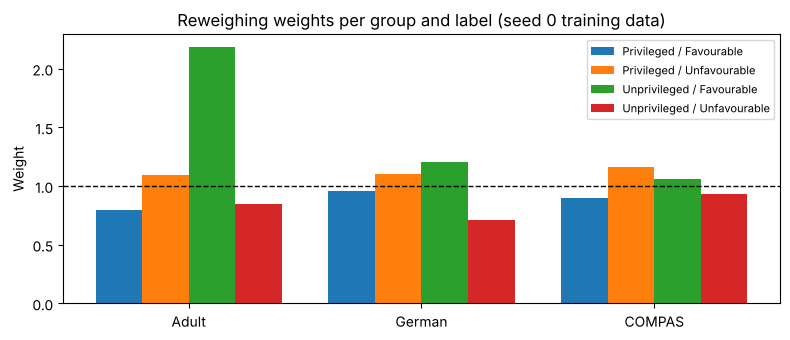

In [8]:
wrows = []
for name, (ds, attr) in data.items():
    unpriv, priv = groups(attr)
    train, _ = stratified_split(ds, attr, SEEDS[0])
    rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv).fit(train)
    s = train.protected_attributes[:, train.protected_attribute_names.index(attr)]
    fav = train.labels.ravel() == train.favorable_label
    for grp, gmask in [("Privileged", s == 1), ("Unprivileged", s == 0)]:
        for lab, lmask in [("Favourable", fav), ("Unfavourable", ~fav)]:
            w = {("Privileged", "Favourable"): rw.w_p_fav, ("Privileged", "Unfavourable"): rw.w_p_unfav,
                 ("Unprivileged", "Favourable"): rw.w_up_fav, ("Unprivileged", "Unfavourable"): rw.w_up_unfav}[(grp, lab)]
            wrows.append({"Dataset": name, "Group": grp, "Label": lab,
                          "Count": int((gmask & lmask).sum()), "Weight": float(w)})
weights = pd.DataFrame(wrows)
display(weights.pivot(index=["Group", "Label"], columns="Dataset", values="Weight")[list(data)].round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
combos = ["Privileged / Favourable", "Privileged / Unfavourable", "Unprivileged / Favourable", "Unprivileged / Unfavourable"]
x = np.arange(len(data)); w = 0.2
for i, (g, l) in enumerate([(c.split(" / ")[0], c.split(" / ")[1]) for c in combos]):
    vals = [weights.query("Dataset == @n and Group == @g and Label == @l")["Weight"].iloc[0] for n in data]
    ax.bar(x + (i - 1.5) * w, vals, w, label=combos[i])
ax.axhline(1, ls="--", c="k", lw=1)
ax.set_xticks(x); ax.set_xticklabels(list(data)); ax.set_ylabel("Weight"); ax.legend(fontsize=8)
ax.set_title("Reweighing weights per group and label (seed 0 training data)")
plt.tight_layout(); plt.show()

### Test-set results (mean ± std over 5 seeds)

In [9]:
metrics = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc."]
agg = results.groupby(["Dataset", "Classifier", "Model"])[metrics].agg(["mean", "std"])
table = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " +
                         agg[(m, "std")].map("{:.3f}".format) for m in metrics})
table.loc[list(data)]

DP_Diff            DIR    Consistency  \
Dataset Classifier Model                                                      
Adult   LogReg     Baseline    -0.185 ± 0.003  0.303 ± 0.006  0.944 ± 0.002   
                   Reweighing  -0.102 ± 0.006  0.549 ± 0.019  0.945 ± 0.001   
        Tree       Baseline    -0.176 ± 0.006  0.329 ± 0.012  0.903 ± 0.001   
                   Reweighing  -0.105 ± 0.006  0.560 ± 0.024  0.900 ± 0.003   
German  LogReg     Baseline    -0.136 ± 0.061  0.824 ± 0.073  0.814 ± 0.012   
                   Reweighing  -0.098 ± 0.049  0.874 ± 0.061  0.812 ± 0.013   
        Tree       Baseline    -0.076 ± 0.097  0.905 ± 0.113  0.762 ± 0.008   
                   Reweighing  -0.075 ± 0.036  0.902 ± 0.047  0.757 ± 0.028   
COMPAS  LogReg     Baseline    -0.144 ± 0.019  0.795 ± 0.024  0.858 ± 0.004   
                   Reweighing  -0.132 ± 0.019  0.812 ± 0.024  0.859 ± 0.005   
        Tree       Baseline    -0.146 ± 0.025  0.791 ± 0.030  0.753 ± 0.009   
                   Reweighing  -0.142 ± 0.028  0.793 ± 0.037  0.751 ± 0.009   

                                    Accuracy  Balanced acc.  
Dataset Classifier Model                                     
Adult   LogReg     Baseline    0.845 ± 0.002  0.764 ± 0.002  
                   Reweighing  0.842 ± 0.002  0.751 ± 0.002  
        Tree       Baseline    0.847 ± 0.003  0.767 ± 0.005  
                   Reweighing  0.841 ± 0.003  0.758 ± 0.003  
German  LogReg     Baseline    0.749 ± 0.034  0.681 ± 0.027  
                   Reweighing  0.750 ± 0.039  0.677 ± 0.034  
        Tree       Baseline    0.721 ± 0.008  0.645 ± 0.017  
                   Reweighing  0.717 ± 0.027  0.641 ± 0.025  
COMPAS  LogReg     Baseline    0.667 ± 0.009  0.659 ± 0.009  
                   Reweighing  0.668 ± 0.012  0.659 ± 0.011  
        Tree       Baseline    0.658 ± 0.012  0.650 ± 0.012  
                   Reweighing  0.649 ± 0.013  0.642 ± 0.014

## 6. Before vs after mitigation

"Original labels" = Step 2 (full dataset, no model). "baseline" = classifier without mitigation, "reweighing" = classifier after the full mitigation pipeline (test-set predictions, mean over 5 seeds). Dashed lines show the ideal values.

DP_Diff    DIR  Consistency  Accuracy
Dataset Stage                                                   
Adult   Original labels     -0.199  0.363        0.829       NaN
        LogReg baseline     -0.185  0.303        0.944     0.845
        LogReg reweighing   -0.102  0.549        0.945     0.842
        Tree baseline       -0.176  0.329        0.903     0.847
        Tree reweighing     -0.105  0.560        0.900     0.841
German  Original labels     -0.149  0.795        0.740       NaN
        LogReg baseline     -0.136  0.824        0.814     0.749
        LogReg reweighing   -0.098  0.874        0.812     0.750
        Tree baseline       -0.076  0.905        0.762     0.721
        Tree reweighing     -0.075  0.902        0.757     0.717
COMPAS  Original labels     -0.097  0.840        0.668       NaN
        LogReg baseline     -0.144  0.795        0.858     0.667
        LogReg reweighing   -0.132  0.812        0.859     0.668
        Tree baseline       -0.146  0.791        0.753     0.658
        Tree reweighing     -0.142  0.793        0.751     0.649

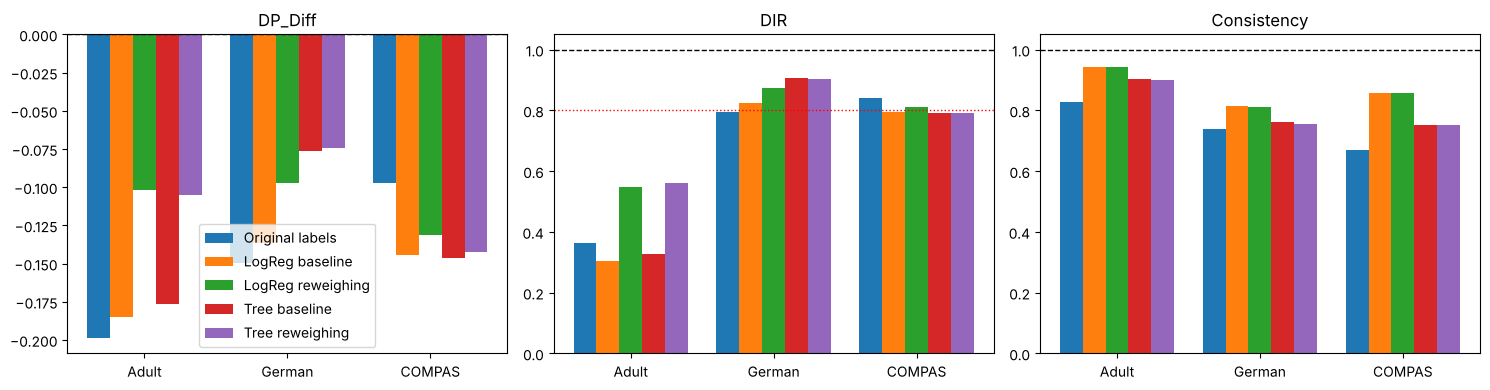

In [10]:
means = results.groupby(["Dataset", "Classifier", "Model"])[metrics].mean()
stages = ["Original labels"]
comp = []
for name in data:
    comp.append({"Dataset": name, "Stage": "Original labels", **before.loc[name].to_dict()})
    for clf_name in CLASSIFIERS:
        for model in ["Baseline", "Reweighing"]:
            st = f"{clf_name} {model.lower()}"
            if st not in stages: stages.append(st)
            comp.append({"Dataset": name, "Stage": st, **means.loc[(name, clf_name, model)].to_dict()})
comparison = pd.DataFrame(comp).set_index(["Dataset", "Stage"])
display(comparison[["DP_Diff", "DIR", "Consistency", "Accuracy"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(len(data)); w = 0.16
for ax, (m, ideal) in zip(axes, [("DP_Diff", 0), ("DIR", 1), ("Consistency", 1)]):
    for i, st in enumerate(stages):
        vals = [comparison.loc[(n, st), m] for n in data]
        ax.bar(x + (i - 2) * w, vals, w, label=st)
    ax.axhline(ideal, ls="--", c="k", lw=1)
    if m == "DIR":
        ax.axhline(0.8, ls=":", c="r", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(list(data)); ax.set_title(m)
axes[0].legend()
plt.tight_layout(); plt.show()